# 🔍 Interactive KNN Classification Demo  
### *Understand how K-Nearest Neighbors works with real-time visualization*

This notebook demonstrates the **K-Nearest Neighbors (KNN)** algorithm for **binary classification** using a 2D dataset (Age vs. Income).  

✅ **You can**:  
- Adjust a **new customer’s Age and Income**  
- Choose the number of neighbors (**k**)  
- Click **“Regenerate Data”** to see how KNN behaves on different datasets  
- See **live updates** of predictions and nearest neighbors  

> 💡 **Great for learning machine learning fundamentals!**

## 📘 What is the K-Nearest Neighbors (KNN) Algorithm?

**KNN** is a simple, intuitive, and **non-parametric** supervised learning algorithm used for **classification** and **regression**.

### 🔑 Core Idea:
> *"Tell me who your neighbors are, and I’ll tell you who you are."*

- Given a new data point, KNN finds the **k closest points** in the training set.
- For **classification**, it assigns the **most common class** among those k neighbors.

### 📏 Distance Metric (Used Here):

The different distance between two points \((x_1, y_1)\) and \((x_2, y_2)\) is:
$$
\text{Euclidean} = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}
$$
Straight-line (“as the crow flies”) distance.
<br><br>
$$
\text{Manhattan}(P, Q) = |x_1 - x_2| + |y_1 - y_2|
$$
Sum of absolute differences — like walking city blocks in a grid.
<br><br>
$$
\text{Chebyshev}(P, Q) = \max\left( |x_1 - x_2|,\; |y_1 - y_2| \right)
$$
Maximum deviation along any single axis.<br><br>
$$
\text{Minkowski}(P, Q) = \left( |x_1 - x_2|^p + |y_1 - y_2|^p \right)^{1/p}
$$

When **p = 1** → Manhattan  
When **p = 2** → Euclidean  
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;As **p → ∞** → Chebyshev  

### ⚙️ Key Hyperparameter:
- **k**: Number of neighbors to consider  
  - Small **k** → sensitive to noise (overfitting)  
  - Large **k** → smoother decision boundary (underfitting)  
  - Usually choose **odd k** to avoid ties in binary classification

## 2. Import Libraries

In [ ]:
# @title
# Install required packages (usually pre-installed in Colab, but safe to include)
!pip install ipywidgets matplotlib pandas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import ipywidgets as widgets
from IPython.display import display, clear_output

# Enable widget support in Colab
from google.colab import output
output.enable_custom_widget_manager()

## 3. Define Training Data

In [ ]:
# Training dataset
# Create the DataFrame with 10 scattered data points
data = {
    'Point': ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'],
    'Age':   [22, 48, 31, 27, 40, 19, 52, 34, 45, 29],
    'Income': [35, 88, 62, 42, 55, 28, 72, 48, 66, 58],
    'Buys':  ['No', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'No', 'Yes', 'No']
}
df = pd.DataFrame(data)
df

,Point,Age,Income,Buys
0,A,22,35,No
1,B,48,88,Yes
2,C,31,62,Yes
3,D,27,42,No
4,E,40,55,Yes
5,F,19,28,No
6,G,52,72,Yes
7,H,34,48,No
8,I,45,66,Yes
9,J,29,58,No


## Plotting the data into a 2D graph

2. **Each dot represent a customer**:
   - 🔴 **Red dots**: Customers who did **not** buy (`No`)
   - 🔵 **Blue dots**: Customers who **did** buy (`Yes`)

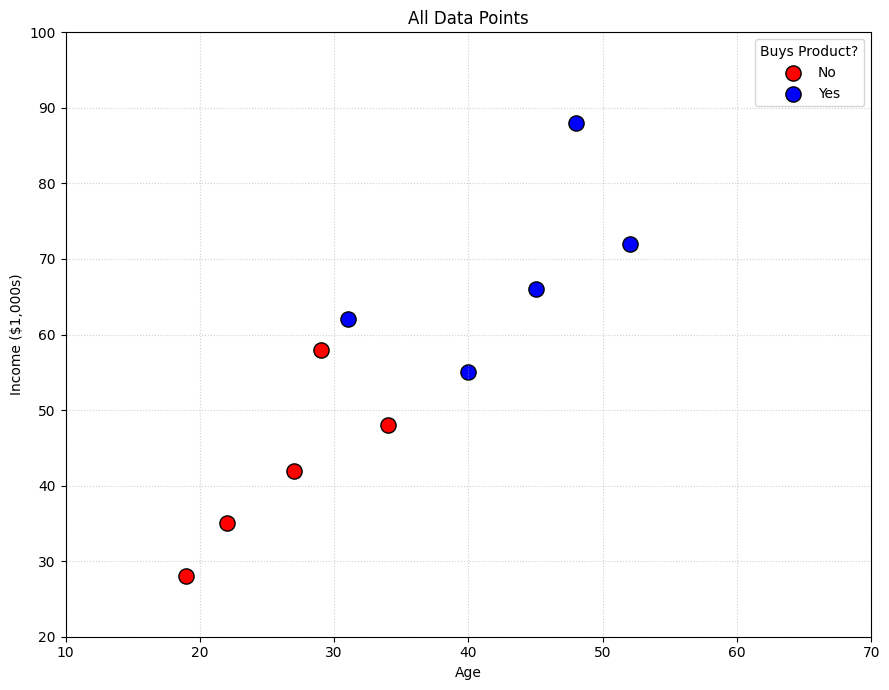

In [ ]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot
plt.figure(figsize=(9, 7))

# Color mapping: No → red, Yes → blue (as requested)
colors = {'No': 'red', 'Yes': 'blue'}

# Plot all training points
for label in df['Buys'].unique():
    subset = df[df['Buys'] == label]
    plt.scatter(subset['Age'], subset['Income'],
                color=colors[label],
                s=120,
                edgecolor='black',
                label=label)

plt.xlabel('Age')
plt.ylabel('Income ($1,000s)')
plt.title('All Data Points')
plt.legend(title="Buys Product?")
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(10, 70)
plt.ylim(20, 100)
plt.tight_layout()
plt.show()

## 🛠️ How to Use This Interactive Demo

1. **Adjust the sliders**:
   - **Age**: Set the customer’s age (15–65)
   - **Income**: Set monthly income in **$1,000s** (20–100)
   - **k**: Choose number of neighbors (1, 3, 5, 7, or 9)

2. **Watch the plot update in real time**:
   - 🔴 **Red dots**: Customers who did **not** buy (`No`)
   - 🔵 **Blue dots**: Customers who **did** buy (`Yes`)
   - 🟢 **Green X**: Your new customer
   - 🟡 **Gold rings**: The **k nearest neighbors**

3. **Click “🔄 Regenerate Data”**:
   - Generates a **new random dataset** with 10 scattered points
   - Helps you see how KNN behaves under different data distributions

4. **Read the prediction** below the plot:
   - Final class (`Yes` or `No`)
   - List of neighbors and their distances

> 🎯 **Try this**: Set Age=33, Income=55, k=3 → then regenerate data 3 times. Notice how the prediction can change!

In [ ]:
# @title
# --- Generate scattered dataset ---
def generate_scattered_data():
    np.random.seed()
    n = 10
    age_no = np.random.normal(28, 8, n//2)
    income_no = np.random.normal(38, 12, n//2)
    age_yes = np.random.normal(44, 9, n//2)
    income_yes = np.random.normal(72, 14, n//2)

    df = pd.DataFrame({
        'Age': np.concatenate([age_no, age_yes]),
        'Income': np.concatenate([income_no, income_yes]),
        'Buys': ['No']*(n//2) + ['Yes']*(n//2)
    })
    df['Age'] = np.clip(df['Age'], 15, 65).round(1)
    df['Income'] = np.clip(df['Income'], 20, 100).round(1)
    return df

# df = generate_scattered_data()

# --- DISTANCE FUNCTIONS ---
def euclidean(p1, p2):
    p1, p2 = np.asarray(p1), np.asarray(p2)
    return np.sqrt(np.sum((p1 - p2) ** 2))

def manhattan(p1, p2):
    p1, p2 = np.asarray(p1), np.asarray(p2)
    return np.sum(np.abs(p1 - p2))

def chebyshev(p1, p2):
    p1, p2 = np.asarray(p1), np.asarray(p2)
    return np.max(np.abs(p1 - p2))

def minkowski(p1, p2, p=3):
    p1, p2 = np.asarray(p1), np.asarray(p2)
    return np.sum(np.abs(p1 - p2) ** p) ** (1 / p)

distance_metrics = {
    'Euclidean (L2)': euclidean,
    'Manhattan (L1)': manhattan,
    'Chebyshev (L∞)': chebyshev,
    'Minkowski (p=3)': lambda a, b: minkowski(a, b, p=3)
}

# --- WIDGETS ---
age_slider = widgets.IntSlider(value=33, min=15, max=65, step=1, description='👤 Age:')
income_slider = widgets.IntSlider(value=55, min=20, max=100, step=1, description='💰 Income ($1k):')
k_slider = widgets.IntSlider(value=3, min=1, max=9, step=2, description='🔢 k:')
distance_dropdown = widgets.Dropdown(
    options=list(distance_metrics.keys()),
    value='Euclidean (L2)',
    description='📏 Metric:',
)
regen_button = widgets.Button(description="🔄 Regenerate Data", button_style='info')
output_area = widgets.Output()

# --- DRAW DISTANCE VISUALS ---
def draw_distance_visuals(ax, query, neighbor, metric_name):
    qx, qy = query
    nx, ny = neighbor

    if metric_name == 'Manhattan (L1)':
        # Draw L-shaped path: (qx,qy) -> (nx,qy) -> (nx,ny)
        ax.plot([qx, nx], [qy, qy], color='orange', linewidth=2, linestyle='-')
        ax.plot([nx, nx], [qy, ny], color='orange', linewidth=2, linestyle='-')

    elif metric_name == 'Chebyshev (L∞)':
        # Draw square centered at query with half-side = distance
        dist = chebyshev(query, neighbor)
        # Square from (qx-dist, qy-dist) to (qx+dist, qy+dist)
        square = plt.Rectangle(
            (qx - dist, qy - dist), 2*dist, 2*dist,
            linewidth=1.5, edgecolor='purple', facecolor='none',
            linestyle='--', alpha=0.7
        )
        ax.add_patch(square)

    # Euclidean & Minkowski: just the straight line (already drawn in main plot)
    # So we do nothing extra here

# --- UPDATE FUNCTION ---
def update_plot(change=None):
    global df
    age = age_slider.value
    income = income_slider.value
    k = k_slider.value
    metric_name = distance_dropdown.value
    dist_func = distance_metrics[metric_name]

    query = np.array([age, income])

    df['Distance'] = df.apply(
        lambda row: dist_func(query, np.array([row['Age'], row['Income']])),
        axis=1
    )
    neighbors = df.nsmallest(k, 'Distance')
    prediction = Counter(neighbors['Buys']).most_common(1)[0][0]

    with output_area:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(9, 7))

        # Plot data points
        for label, color in [('No', 'red'), ('Yes', 'blue')]:
            subset = df[df['Buys'] == label]
            ax.scatter(subset['Age'], subset['Income'],
                       color=color, s=120, edgecolor='k', linewidth=0.8, label=label)

        # Query point
        ax.scatter(age, income, color='green', s=220, marker='X',
                   edgecolor='k', linewidth=1.5, label='New Customer')

        # Neighbors (gold rings)
        ax.scatter(neighbors['Age'], neighbors['Income'],
                   facecolors='none', edgecolors='gold', s=300, linewidth=3, label='Neighbors')

        # Draw distance visuals for each neighbor
        for _, row in neighbors.iterrows():
            neighbor_point = (row['Age'], row['Income'])
            # Always draw straight line (for reference)
            ax.plot([age, row['Age']], [income, row['Income']],
                    color='gray', linestyle='--', alpha=0.6)
            # Draw metric-specific visuals
            draw_distance_visuals(ax, (age, income), neighbor_point, metric_name)

        # Styling
        ax.set_xlabel('Age', fontsize=12)
        ax.set_ylabel('Income ($1,000s)', fontsize=12)
        ax.set_title(f'KNN Prediction (k={k}, {metric_name}): "{prediction}"', fontsize=13)
        ax.legend(title="Class", loc='upper left')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.set_xlim(15, 65)
        ax.set_ylim(20, 105)
        plt.tight_layout()
        plt.show()

        # Print details
        print(f"\n🟢 Customer: Age={age}, Income={income}")
        print(f"📏 Distance Metric: {metric_name}")
        print(f"Nearest Neighbors (k={k}):")
        for i, (_, row) in enumerate(neighbors.iterrows(), 1):
            print(f"  {i}. Age={row['Age']}, Income={row['Income']}, Buys={row['Buys']} (d={row['Distance']:.2f})")
        print(f"\n✅ Final Prediction: '{prediction}'")

# --- LINK WIDGETS ---
age_slider.observe(update_plot, names='value')
income_slider.observe(update_plot, names='value')
k_slider.observe(update_plot, names='value')
distance_dropdown.observe(update_plot, names='value')

def on_regen_click(b):
    global df
    df = generate_scattered_data()
    update_plot()

regen_button.on_click(on_regen_click)

# --- LAYOUT ---
controls = widgets.VBox([
    age_slider,
    income_slider,
    k_slider,
    distance_dropdown,
    regen_button,
])

ui = widgets.VBox([
    widgets.HTML("<h3>🎛️ Interactive KNN with Distance Visualization</h3>"),
    controls,
    output_area
])

display(ui)
update_plot()

## 💡 Tips for Experimentation

- **Try edge cases**:  
  - Very high income + young age → does it predict "Yes"?  
  - Middle values with k=1 vs k=7 → how does prediction change?

- **Observe overfitting**:  
  With **k=1**, the model may flip predictions with tiny changes → that’s **overfitting**!

- **Real-world note**:  
  In practice, always **scale your features** (e.g., using `StandardScaler`) so Age and Income contribute equally to distance.

## 🚀 Want to go further?
- Add **feature scaling toggle**
- Visualize **decision boundaries** (computationally heavier)
- Try **distance-weighted voting** (closer neighbors count more)

> 🙌 **You’ve just explored one of the most intuitive ML algorithms**